# 02. Почему модель так решает и держится ли она вне привычных условий

**Этапы 4–5 проекта.** В первом ноутбуке мы смотрели на данные, потом обучили модель (логистическая регрессия, macro-F1 0.956 на тесте). Здесь два вопроса:

1. **Интерпретация.** На какие гены смотрит модель? Если это известные маркеры тканей (альбумин для печени, тиреоглобулин для щитовидной железы), значит модель выучила биологию, а не случайный шум.
2. **Устойчивость.** Работает ли модель там, где её не учили: на **метастазах**, на **больницах, которых она не видела**, и с **малым числом генов**?

Сами расчёты делают скрипты `src/interpret.py` и `src/robustness.py`. Ноутбук только читает их результаты и объясняет их.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display

R = "../results"
pd.set_option("display.width", 120)

## Сначала про качество данных: «платформенные» гены

Когда я впервые готовил данные, я выбросил все гены, у которых есть хоть один пропуск. Пропало около 4 000 генов, и среди них были известные маркеры. Разбор показал две разные группы:

- **~3 000 генов отсутствуют в 5–20% образцов**, и все эти образцы из нескольких партий (STAD, UCEC, OV, ESCA, COAD, READ), измеренных на другой версии платформы. Если заполнить такие пропуски, модель научится узнавать **партию**, а не опухоль: «нет значения → значит, это желудок». Поэтому эти гены исключены. Цена: потеряны маркеры NKX2-1 и SFTPC (лёгкое), OLIG2 (глиома), TYR (меланома).
- **~1 100 генов с редкими пропусками** (меньше 1% образцов, 27 опухолей желудка). Их оставили и заполняют медианой обучающей выборки внутри пайплайна.

Мораль: пропуски в данных бывают не случайными, и их структура может «подсказать» ответ. Перед тем как чистить данные, надо посмотреть, *где* пропуски.

## 4. Интерпретация: вклад каждого гена

Для логистической регрессии вклад гена в решение считается точно: **коэффициент гена × его стандартизованная экспрессия**. Это ровно то, что выдаёт SHAP (`LinearExplainer`) с обучающими данными в качестве фона; я проверил, разница 2·10⁻⁸. Сумма вкладов всех генов плюс свободный член даёт балл класса.

Для каждого типа рака я усреднил вклады по опухолям этого типа в тестовой выборке и отсортировал гены. Оранжевым отмечены маркеры из учебников, **список которых я составил до того, как посмотрел на результаты**, чтобы не подгонять.

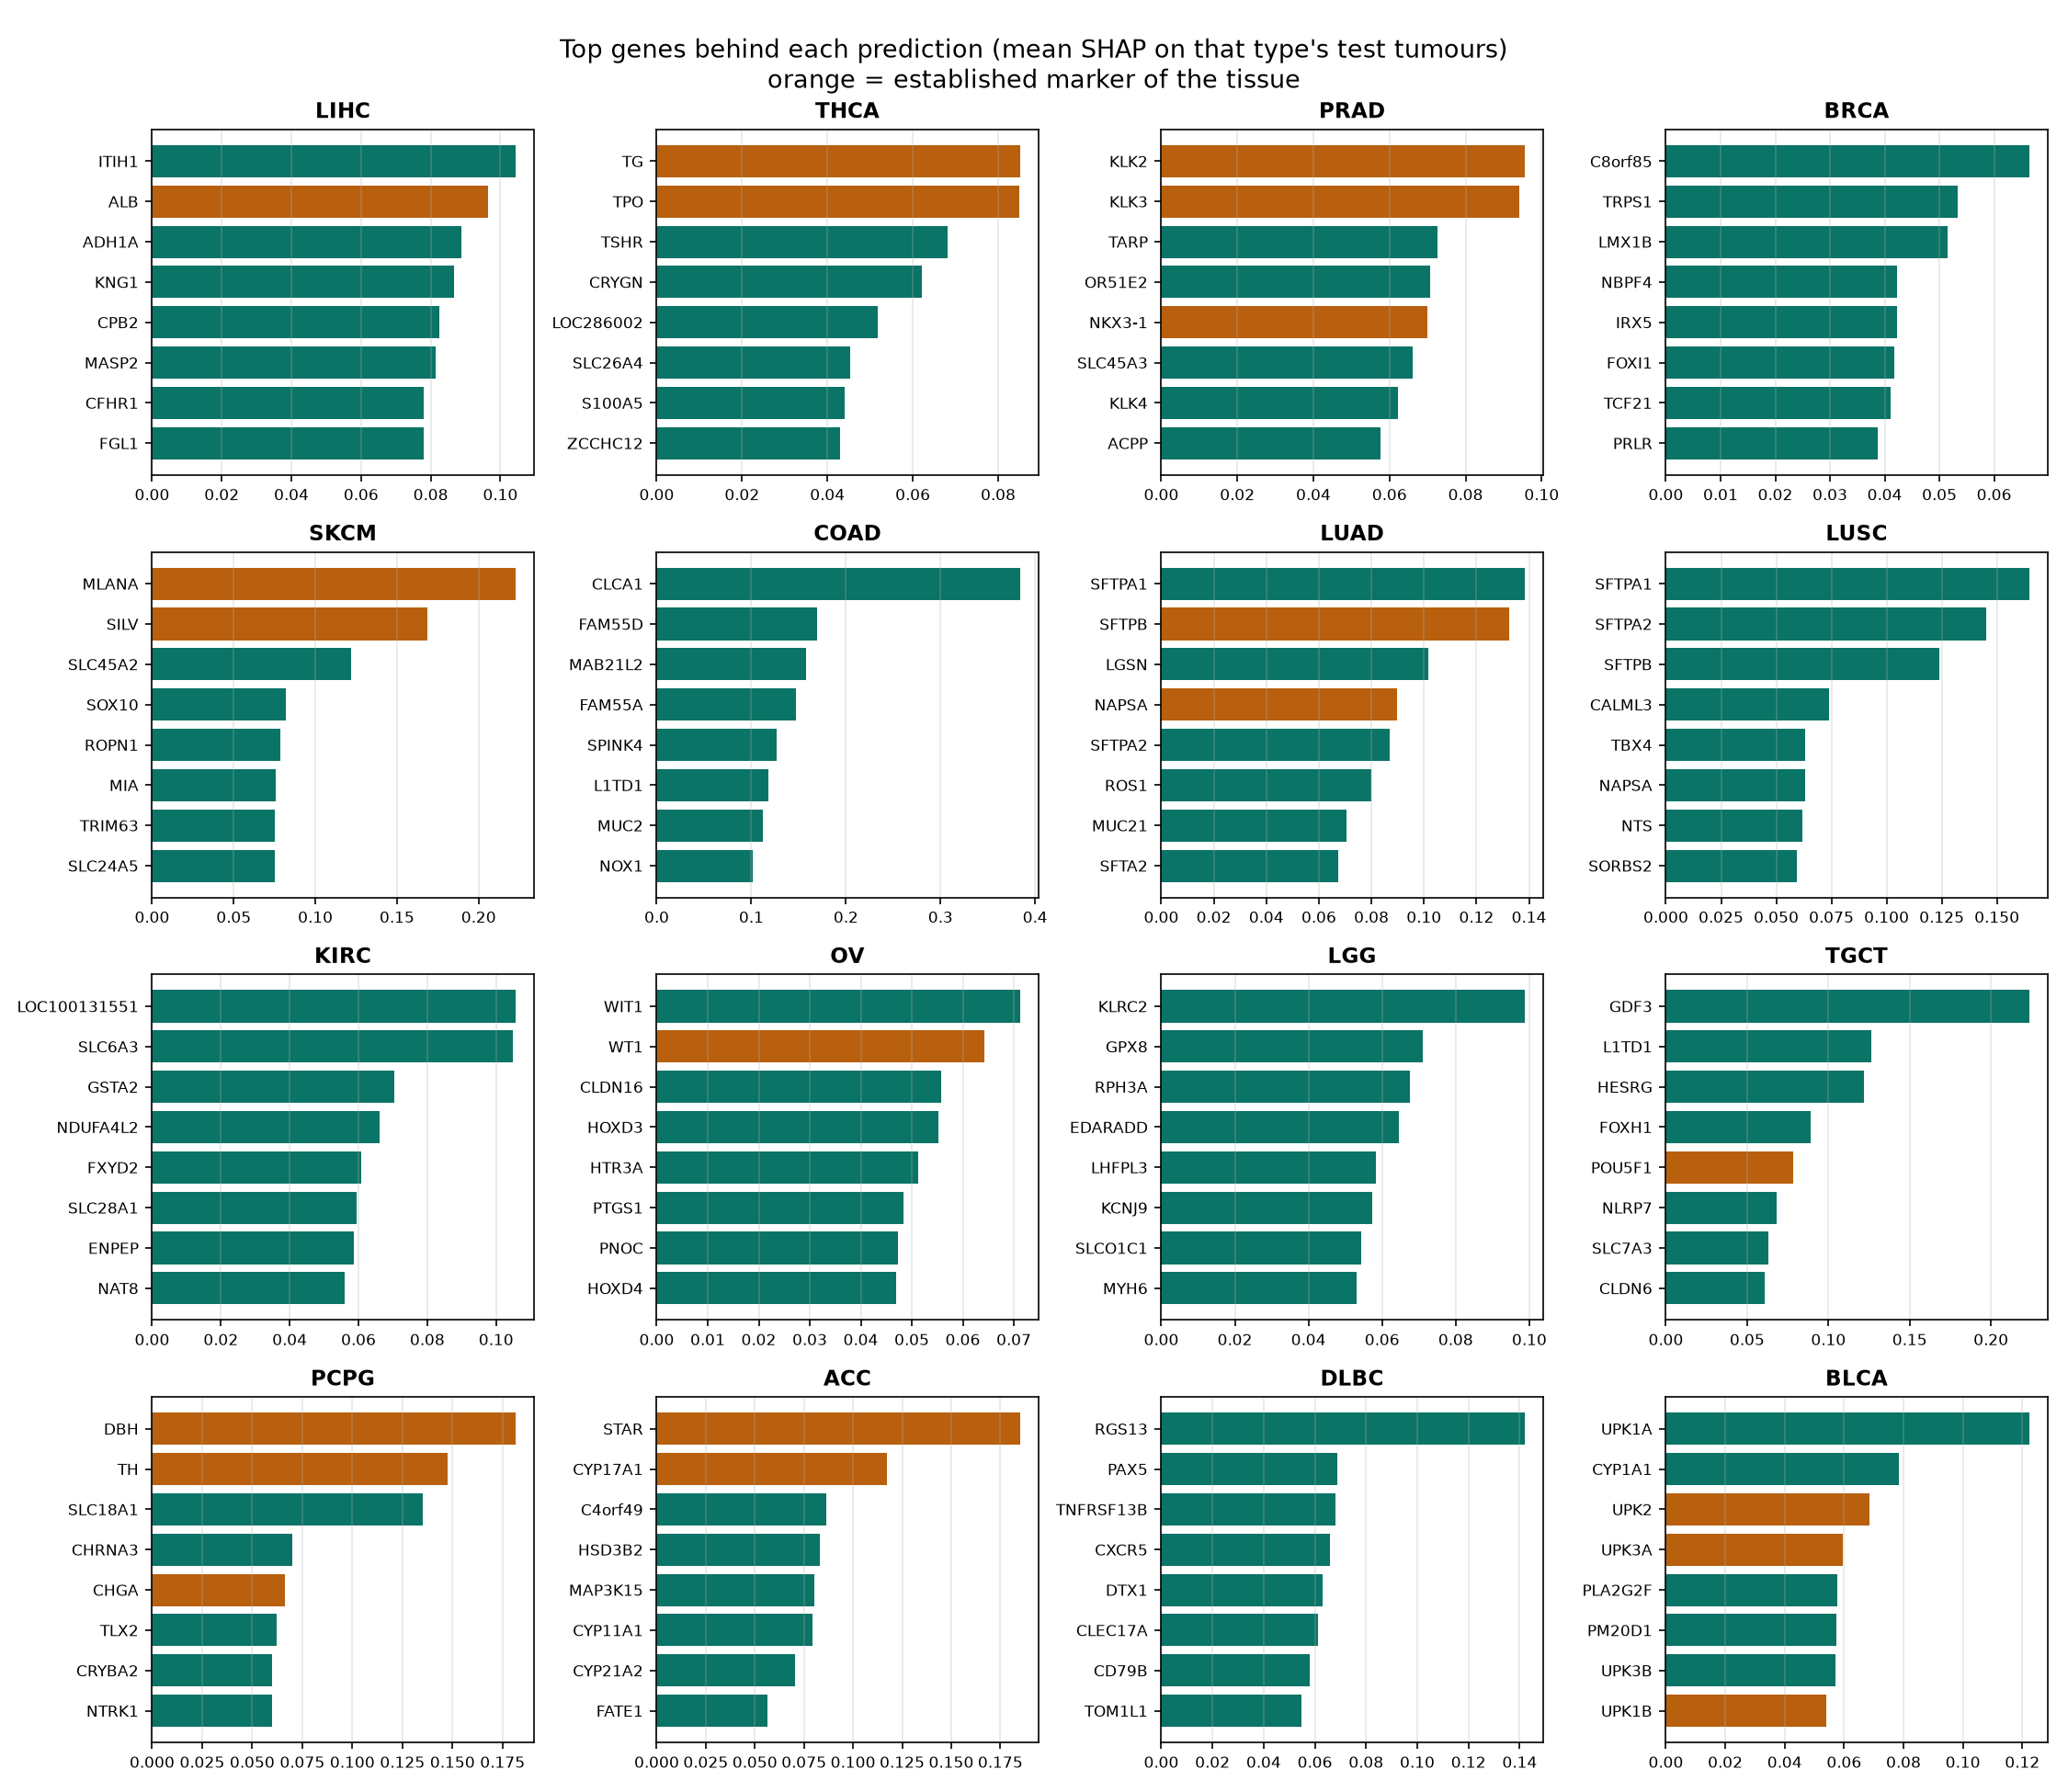

In [2]:
display(Image(f"{R}/figures/shap_top_genes.png", width=1000))

### Проверка по известным маркерам

Ранг 1 значит, что ген самый важный для своего типа рака из 5 000 генов модели.

In [3]:
markers = pd.read_csv(f"{R}/marker_check.csv")
found = markers.dropna(subset=["rank"])
print(f"маркеров в списке: {len(markers)}; есть среди генов модели: {len(found)}")
print(f"в топ-10 для своей ткани: {(found['rank'] <= 10).sum()}, в топ-50: {(found['rank'] <= 50).sum()}")
print("нет среди генов модели:", ", ".join(markers.loc[~markers.in_model, "marker"].unique()))
found.assign(rank=found["rank"].astype(int)).sort_values("rank")[["cancer_type", "marker", "rank"]].reset_index(drop=True)

маркеров в списке: 60; есть среди генов модели: 55
в топ-10 для своей ткани: 27, в топ-50: 42
нет среди генов модели: APOA2, DCT, NANOG, NR5A1


,cancer_type,marker,rank
0,THCA,TG,1
1,PRAD,KLK2,1
2,UVM,MLANA,1
3,SKCM,MLANA,1
4,ACC,STAR,1
5,PCPG,DBH,1
6,PRAD,KLK3,2
7,SKCM,SILV,2
8,OV,WT1,2
9,LUAD,SFTPB,2


**Что видно:**

- Классические маркеры стоят на самом верху: **STAR** (кора надпочечника), **MLANA** (меланома, кожная и увеальная), **KLK2** (простата), **TG** (щитовидная железа), **DBH** (феохромоцитома), **ALB** (печень), **WT1** (яичник), **SFTPB** (лёгкое), **UPK2/UPK3B** (уротелий, мезотелий). Модель выучила биологию тканей.
- Маркеры, общие для нескольких типов, стоят низко: **PAX8** есть и в почке, и в яичнике, и в эндометрии; **KRT5** есть во всех плоскоклеточных раках. Модели нужны гены, которые *различают* классы, а общий маркер ничего не различает. Это не ошибка, а разница между «маркером ткани» и «различающим признаком».
- **Неожиданный сигнал в плоскоклеточном раке лёгкого (LUSC):** главные гены там сурфактанты SFTPA1/SFTPA2/SFTPB. Опухолевые клетки LUSC их не производят, их производят нормальные альвеолы. Значит, модель частично узнаёт **окружающую нормальную ткань лёгкого** в образце. Для первичной опухоли это работает, но для метастаза (в печени, в лимфоузле) такой подсказки не будет. Это прогноз, который проверим ниже.

In [4]:
top = pd.read_csv(f"{R}/top_genes_per_type.csv")
top[top["rank"] <= 5].pivot(index="cancer_type", columns="rank", values="gene")

rank,1,2,3,4,5
cancer_type,,,,,
ACC,STAR,CYP17A1,C4orf49,HSD3B2,MAP3K15
BLCA,UPK1A,CYP1A1,UPK2,UPK3A,PLA2G2F
BRCA,C8orf85,TRPS1,LMX1B,NBPF4,IRX5
CESC,TSIX,TCP11,SMC1B,SERPINB3,CDKN2A
CHOL,CHST4,ANKRD1,SFRP5,TMEM156,TNFSF14
COAD,CLCA1,FAM55D,MAB21L2,FAM55A,SPINK4
DLBC,RGS13,PAX5,TNFRSF13B,CXCR5,DTX1
ESCA,RPPH1,MUC17,CTCFL,RMRP,SLC9A3
GBM,MFSD2B,SLC6A10P,LGALS9C,HLA-G,SULT1A2


## 5. Устойчивость

Важное правило: тестовая выборка уже использована один раз и больше не трогается. Проверки 5.2 и 5.3 используют только обучающую и валидационную выборки.

### 5.1. Метастазы

В TCGA есть 394 метастаза, которые модель не видела. Она училась только на первичных опухолях, а метастаз растёт в чужом органе (лимфоузел, кожа, печень).

In [5]:
rob = json.load(open(f"{R}/robustness.json"))
m = rob["metastases"]
print(f"всего метастазов: {m['n']}; точность {m['accuracy']:.3f}; правильный ответ в топ-3: {m['top3_accuracy']:.3f}")
print(f"меланома: {m['melanoma']['accuracy']:.3f} (n={m['melanoma']['n']}); остальные: {m['other']['accuracy']:.3f} (n={m['other']['n']})")
print("ошибки на меланоме:", m["melanoma_errors"])
other = pd.DataFrame(m["other_cases"]).assign(correct=lambda d: d.cancer_type == d.predicted)
other.groupby("cancer_type").correct.agg(верно="sum", всего="count")

всего метастазов: 394; точность 0.924; правильный ответ в топ-3: 0.980
меланома: 0.932 (n=368); остальные: 0.808 (n=26)
ошибки на меланоме: {'SARC': 12, 'UVM': 4, 'UCS': 3, 'DLBC': 2, 'LUAD': 2, 'CHOL': 1, 'ACC': 1}


,верно,всего
cancer_type,,
BRCA,5,7
CESC,1,2
COAD,1,1
ESCA,0,1
HNSC,2,2
PAAD,1,1
PCPG,2,2
PRAD,1,1
SARC,0,1


In [6]:
other[~other.correct]

,sample,cancer_type,predicted,correct
2,TCGA-BH-A1ES-06,BRCA,LIHC,False
3,TCGA-BH-A1FE-06,BRCA,MESO,False
12,TCGA-HM-A6W2-06,CESC,UCEC,False
20,TCGA-SI-A71O-06,SARC,LUAD,False
25,TCGA-V5-A7RC-06,ESCA,LUSC,False


**Что видно:**

- Почти все метастазы в TCGA (368 из 394) это меланома, её модель узнаёт в 93% случаев. Самая частая ошибка: **саркома** (12). Это объяснимо: часть меланом веретеноклеточные и выглядят как саркома даже под микроскопом, а метастазы в мягких тканях окружены соединительной тканью. Ещё 4 раза модель назвала **увеальную меланому**, то есть ту же клеточную линию (меланоциты), но из глаза.
- Для остальных типов выборка маленькая (26), точность 81%. Ошибки показательны: метастазы рака груди названы **раком печени** и **мезотелиомой**. Скорее всего, эти образцы взяты из печени и плевры, и модель увидела окружающую нормальную ткань. Это тот же эффект, что и с сурфактантами в LUSC.
- Вывод: на метастазах качество ниже, чем на первичных опухолях (92% против 97%), и главная причина в примеси ткани органа, где вырос метастаз. В реальном применении это первое, что нужно было бы исправлять (например, вычитать сигнатуру нормальной ткани).

### 5.2. Больницы, которых модель не видела

В первом ноутбуке мы видели, что по экспрессии можно угадать больницу чаще случайного. Опасность: модель может выучить «почерк» больницы (протоколы забора и хранения), а в новой больнице этот почерк будет другим.

Проверка: 5-кратная кросс-валидация двумя способами на одних и тех же 8 224 опухолях:
- **случайное разбиение** (как обычно);
- **разбиение по больницам** (`GroupKFold`): все опухоли одной больницы попадают в один фолд, поэтому при проверке модель видит только незнакомые больницы.

In [7]:
s = rob["sites"]
print(f"опухолей: {s['n_tumours']}, больниц: {s['n_sites']}")
pd.DataFrame({k: s[k] for k in ("random_split", "unseen_sites")}).T[["macro_f1", "accuracy", "scored"]]

опухолей: 8224, больниц: 680


,macro_f1,accuracy,scored
random_split,0.938332,0.956712,8224.0
unseen_sites,0.916222,0.941513,8224.0


**Что видно:** на новых больницах macro-F1 падает с 0.938 до 0.916, а точность с 95.7% до 94.2%. Падение есть, значит «почерк» больницы модель немного использует, но оно небольшое. Основной сигнал модели биологический и переносится на новые центры.

Почему падение вообще есть: в TCGA некоторые больницы присылали в основном один тип рака, и при разбиении по больницам часть типов теряет заметную долю обучающих примеров. Так что 0.916 это скорее нижняя оценка.

### 5.3. Сколько генов на самом деле нужно

Я отсортировал гены по весу в полной модели (обученной на train), затем обучал модель только на топ-k генах и оценивал её на валидации.

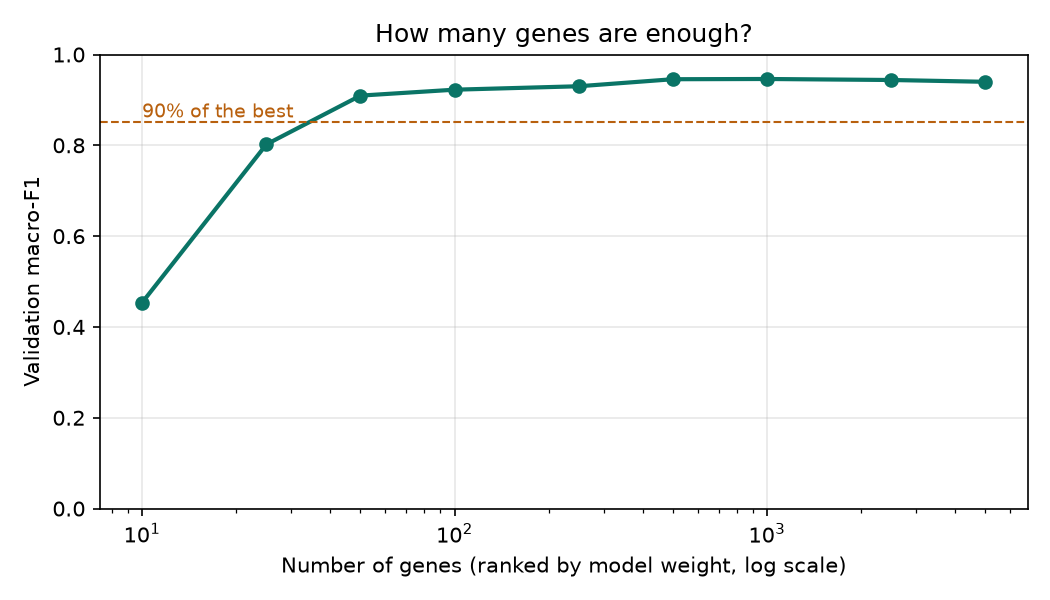

,genes,val_macro_f1
0,10,0.453504
1,25,0.802090
2,50,0.909464
3,100,0.922491
4,250,0.930084
5,500,0.945557
6,1000,0.946068
7,2500,0.943847
8,5000,0.939886


In [8]:
display(Image(f"{R}/figures/gene_budget.png", width=700))
pd.read_csv(f"{R}/gene_budget.csv")

**Что видно:**

- **50 генов** уже дают macro-F1 0.909, это больше 90% от лучшего результата. С 10 генами модель различает меньше половины типов.
- **500 генов** дают максимум (0.946), а добавление генов дальше не помогает и даже чуть ухудшает результат (0.940 на 5 000): лишние гены добавляют шум.
- Практический смысл: тест на основе экспрессии не обязан измерять весь геном. Панели из нескольких сотен генов (как NanoString или таргетная RNA-seq) в принципе достаточно. Это согласуется с коммерческими тестами на происхождение опухоли, которые используют от десятков до нескольких сотен генов.

Оговорка: гены отбирались по одной модели на одной выборке. Для настоящей панели отбор надо было бы повторить внутри кросс-валидации и проверить на независимых данных.

## Итоги этапов 4–5

| Вопрос | Ответ |
|---|---|
| Выучила ли модель биологию? | Да: 27 из 55 известных маркеров в топ-10 своей ткани, многие на 1–3 месте |
| Есть ли «подсказки» не из опухоли? | Да: нормальная ткань в образце (сурфактанты в LUSC) и платформенные пропуски (исключены) |
| Метастазы | Точность 92%, топ-3 98%; ошибки от ткани органа, где вырос метастаз |
| Новые больницы | macro-F1 0.938 → 0.916: небольшое падение |
| Сколько генов нужно | 50 генов дают 90% качества, 500 дают максимум |

**Ограничения.** Это учебный и исследовательский проект, а не диагностический инструмент. Метастазов не-меланом мало (26), независимого внешнего набора данных (другие клиники, клеточные линии) пока нет.